# Die Methode der Lagrange-Multiplikatoren

Wir betrachten zunächst eine Funktion mehrerer Variablen und möchten z. B. deren Minimum unter einer Nebenbedingung finden. Um diese Frage zu beantworten erinnern wir uns zunächst an das Vorgehen ohne Nebenbedingung.


## Extrempunkte einer Funktion mehrerer Variablen

Wir wählen zunächst einen beliebigen Punkt und fragen: Wie ändert sich der Funktionswert, wenn wir uns von diesem Punkt aus ein kleines Stück in eine beliebige Richtung bewegen? Um diese Frage zu beantworten schauen wir uns das lokale Verhalten der Funktion an. 

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
from scripts.lagrange_figures import (
    unconstrained_displacements,
    allowed_displacements,
    constrained_extremum,
)

## Wie ändert sich die Funktion in der Umgebung eines Punktes?

Wir betrachten eine glatte Funktion $f(x_1,\ldots,x_n)$ und einen Punkt $\mathbf x$ im Inneren ihres Definitionsbereichs. Eine (kleine) Verschiebung sei $d\mathbf x=(dx_1,\ldots,dx_n)^{\mathsf T}$. Der **lineare Anteil der Funktionsänderung** definiert das **totale Differential**:

$$
\boxed{df=\sum_{i=1}^n\frac{\partial f}{\partial x_i}\,dx_i
=\nabla f\cdot d\mathbf x.}
$$

Alle partiellen Ableitungen werden am Ausgangspunkt $\mathbf x$ ausgewertet. Für zwei Variablen lautet diese Beziehung beispielsweise einfach

$$
df=\frac{\partial f}{\partial x}\,dx+\frac{\partial f}{\partial y}\,dy.
$$

Das totale Differential beschreibt also, wie sich die Funktion in erster Ordnung ändert, wenn wir uns vom Punkt $\mathbf x$ aus in eine beliebige Richtung bewegen. 

**Was muss an einem Minimum geschehen?** Gäbe es eine Richtung mit einer von null verschiedenen Steigung, dann wäre eine der beiden entgegengesetzten Bewegungsrichtungen eine Abstiegsrichtung. An einem inneren Minimum muss deshalb

$$
df=0\qquad\text{für jede Verschiebungsrichtung }d\mathbf x
$$

gelten. Ohne Nebenbedingung können wir die $dx_i$ unabhängig voneinander wählen. Insbesondere können wir nur $x_1$, nur $x_2$ usw. verändern. Daher muss jeder Koeffizient im totalen Differential verschwinden:

$$
\boxed{\frac{\partial f}{\partial x_1}=\cdots=
\frac{\partial f}{\partial x_n}=0,
\qquad\text{also}\qquad\nabla f=0.}
$$

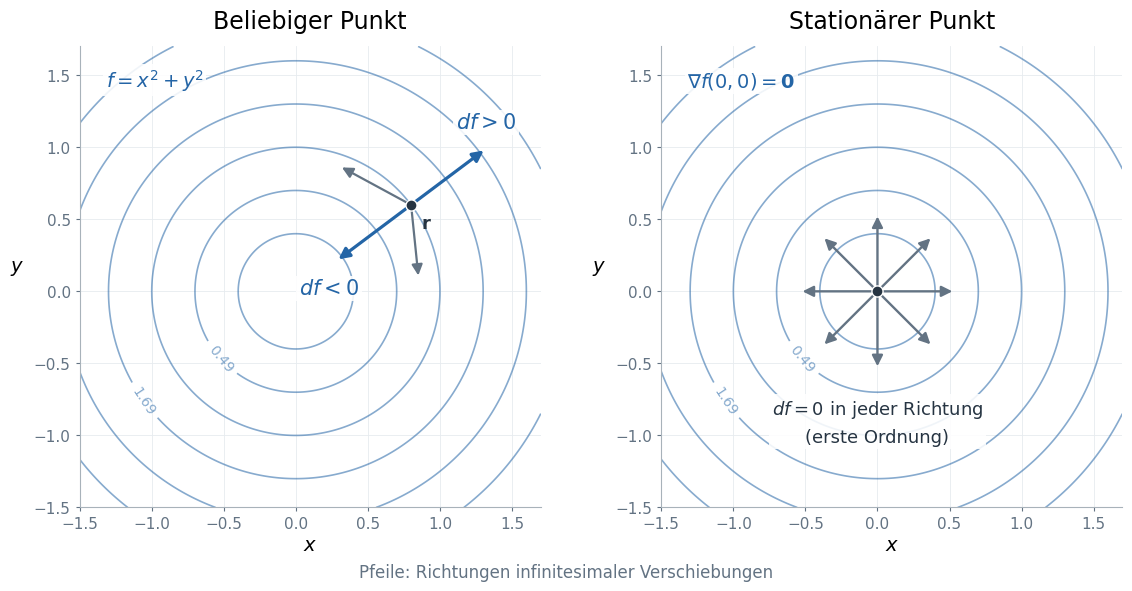

In [9]:
fig = unconstrained_displacements()
plt.show()

*Skizze 1: Höhenlinien von $f(x,y)=x^2+y^2$. Am links dargestellten nichtstationären Punkt gibt es Richtungen mit positiver und negativer Steigung. Am Ursprung verschwindet die Änderung erster Ordnung in jeder Richtung.*

Dass $df=0$ gilt, bedeutet **nicht**, dass sich der Funktionswert bei einem endlichen Schritt überhaupt nicht ändert. Für das dargestellte Minimum ist

$$
df\big|_{(0,0)}=0,
\qquad
f(dx,dy)-f(0,0)=dx^2+dy^2>0
$$

für jede von null verschiedene Verschiebung.

```{note}
Das Verschwinden der ersten Ableitungen ist eine **notwendige**, aber keine hinreichende Bedingung für ein Minimum. Auch an einem Maximum oder Sattelpunkt kann $df=0$ gelten. Beispielsweise hat $f(x,y)=x^2-y^2$ am Ursprung einen Sattelpunkt.
```

## Eine Nebenbedingung schränkt die erlaubten Richtungen ein

Nun soll zusätzlich eine Nebenbedingung in der folgenden Form gelten:

$$
g(x_1,\ldots,x_n)=0
$$

Wir nehmen an, dass auch $g$ glatt ist und $\nabla g\ne0$ am betrachteten Punkt gilt. Die Nebenbedingung beschreibt dort eine glatte Kurve beziehungsweise Fläche. Wir dürfen uns nur entlang dieser bewegen. Für eine solche Bewegung bleibt $g$ konstant; daher gilt

$$
\boxed{dg=\sum_{i=1}^n\frac{\partial g}{\partial x_i}\,dx_i
=\nabla g\cdot d\mathbf x=0.}
$$

Die erlaubten infinitesimalen Verschiebungen liegen also **tangential zur Nebenbedingung** und senkrecht zu $\nabla g$. Die Größen $dx_i$ können jetzt nicht mehr alle unabhängig gewählt werden.

Auf dem Einheitskreis $g(x,y)=x^2+y^2-1=0$ folgt beispielsweise

$$
dg=2x\,dx+2y\,dy=0.
$$

An einem Punkt mit $y\ne0$ ist damit $dy=-(x/y)\,dx$: Die Änderung von $y$ ist durch die gewählte Änderung von $x$ festgelegt.

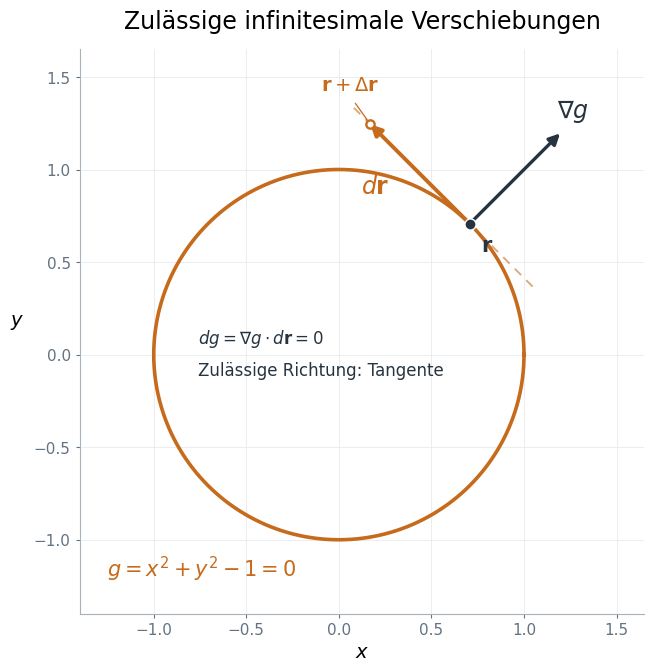

In [10]:
fig = allowed_displacements()
plt.show()

*Skizze 2: Auf dem Kreis ist die Tangentenrichtung erlaubt; eine Bewegung in Normalenrichtung verletzt die Nebenbedingung bereits in erster Ordnung. Der Gradient $\nabla g$ steht senkrecht auf der Tangente.*

In der Skizze ist $\mathbf r=(x,y)^{\mathsf T}$. Der offene Punkt $\mathbf r+\Delta\mathbf r$ markiert das Ende eines endlichen Tangentenschritts außerhalb des Kreises.

Hier beschreibt $dg=0$ die Nebenbedingung **in erster Ordnung**. Ein endlicher gerader Schritt entlang der Tangente liegt im Allgemeinen nicht mehr auf der gekrümmten Kurve. Eine exakt zulässige Bewegung folgt der Kurve selbst.

Am gesuchten Minimum verlangen wir nun nur noch

$$
df=0\qquad\text{für alle }d\mathbf x\text{ mit }dg=0.
$$

Deshalb dürfen wir aus $df=0$ jetzt **nicht** unmittelbar schließen, dass alle partiellen Ableitungen von $f$ verschwinden.

## Der entscheidende Schritt: eine abhängige Verschiebung eliminieren

Wir schreiben kurz $f_i=\partial f/\partial x_i$ und $g_i=\partial g/\partial x_i$. Am gesuchten Punkt seien $df=0$ für alle erlaubten Verschiebungen und $\nabla g\ne0$. Dann ist mindestens eine Ableitung von $g$ ungleich null. Wir nummerieren die Variablen so, dass $g_n\ne0$.

Aus der Nebenbedingung folgt

$$
dx_n=-\frac{1}{g_n}\sum_{i=1}^{n-1}g_i\,dx_i.
$$

Die ersten $n-1$ Verschiebungen sind lokal frei wählbar; $dx_n$ hängt von ihnen ab.

**Wir addieren nun eine Größe, die für jede erlaubte Verschiebung null ist.** Für eine zunächst frei wählbare Zahl $\lambda$ gilt

$$
0=df-\lambda\,dg
=\sum_{i=1}^{n-1}(f_i-\lambda g_i)\,dx_i
+(f_n-\lambda g_n)\,dx_n.
$$

Wir wählen diese eine Zahl so, dass der Koeffizient der **abhängigen** Verschiebung $dx_n$ verschwindet:

$$
\lambda=\frac{f_n}{g_n}
\qquad\Longrightarrow\qquad
f_n-\lambda g_n=0.
$$

Übrig bleibt

$$
\sum_{i=1}^{n-1}(f_i-\lambda g_i)\,dx_i=0.
$$

Diese Gleichung muss für alle **unabhängigen** Verschiebungen $dx_1,\ldots,dx_{n-1}$ gelten. Also verschwinden deren Koeffizienten ebenfalls. Zusammen mit der bereits durch unsere Wahl von $\lambda$ erfüllten letzten Gleichung erhalten wir

$$
\boxed{\frac{\partial f}{\partial x_i}
-\lambda\frac{\partial g}{\partial x_i}=0
\quad(i=1,\ldots,n),
\qquad g(\mathbf x)=0.}
$$

Die Hilfsgröße $\lambda$ heißt **Lagrange-Multiplikator**. Für eine Nebenbedingung benötigen wir genau einen Multiplikator. Das Minuszeichen ist eine Konvention; mit $df+\lambda\,dg$ ändert sich lediglich das Vorzeichen von $\lambda$.

## Geometrische Bedeutung und Lagrange-Funktion

In Vektorschreibweise lauten die Bedingungen

$$
\boxed{\nabla f=\lambda\nabla g,\qquad g=0.}
$$

Am eingeschränkten Extremum hat $\nabla f$ keine Komponente entlang der erlaubten Tangentenrichtungen. Er liegt in der Normalenrichtung der Nebenbedingung: Die beiden Gradienten sind parallel oder antiparallel; auch $\nabla f=0$ ist möglich. Der Gradient von $f$ muss unter einer Nebenbedingung also nicht selbst verschwinden.

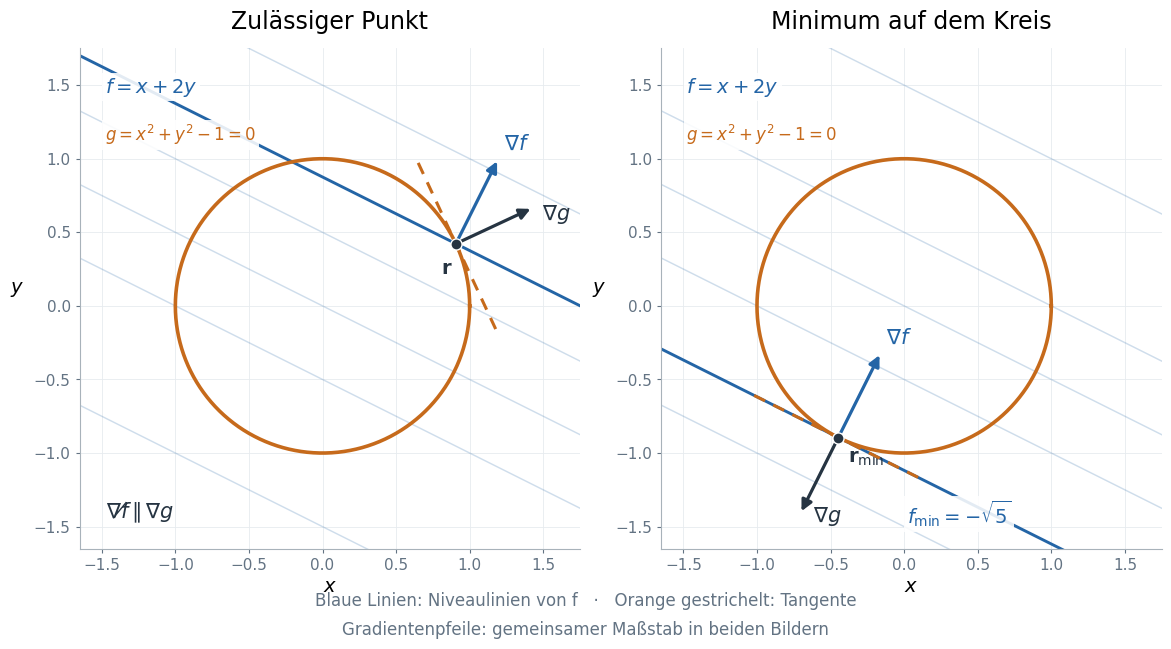

In [11]:
fig = constrained_extremum()
plt.show()

*Skizze 3: $f(x,y)=x+2y$ auf dem Einheitskreis. Links kann sich $f$ entlang des Kreises noch in erster Ordnung ändern. Am Minimum rechts berührt eine Höhenlinie von $f$ den Kreis; $\nabla f$ und $\nabla g$ sind entgegengesetzt gerichtet.*

Wir können die hergeleiteten Gleichungen kompakt in einer Funktion zusammenfassen:

$$
\mathcal L(\mathbf x,\lambda)=f(\mathbf x)-\lambda g(\mathbf x).
$$

Ihr vollständiges Differential ist

$$
d\mathcal L=\sum_{i=1}^n(f_i-\lambda g_i)\,dx_i-g\,d\lambda.
$$

In diesem **erweiterten Variablenraum** behandeln wir $x_1,\ldots,x_n$ und $\lambda$ als unabhängige Variablen. Die Stationaritätsbedingungen lauten

$$
\boxed{\frac{\partial\mathcal L}{\partial x_i}=0
\quad(i=1,\ldots,n),
\qquad
\frac{\partial\mathcal L}{\partial\lambda}=-g=0.}
$$

Damit haben wir $n+1$ Gleichungen für $n+1$ Unbekannte. Wir suchen einen **stationären Punkt** von $\mathcal L$; $\mathcal L$ muss dort kein Minimum besitzen. Ob die gefundene Lösung ein Minimum von $f$ unter der Nebenbedingung ist, prüfen wir anschließend.

## Beispiel: ein Minimum auf dem Einheitskreis

Für das Beispiel aus Skizze 3 ist

$$
\mathcal L(x,y,\lambda)=x+2y-\lambda(x^2+y^2-1).
$$

Die drei Gleichungen sind

$$
1-2\lambda x=0,\qquad
2-2\lambda y=0,\qquad
x^2+y^2=1.
$$

Es folgt $y=2x$ und damit $5x^2=1$. Wir erhalten zwei Kandidaten:

$$
(x,y)=\pm\frac{1}{\sqrt5}(1,2),
\qquad f=\pm\sqrt5.
$$

Die Funktion nimmt auf dem geschlossenen, beschränkten Kreis ein Minimum und ein Maximum an. Da $\nabla g\ne0$ auf dem gesamten Kreis gilt und die beiden Kandidaten alle stationären Punkte erfassen, ist

$$
\boxed{(x_{\min},y_{\min})=
\left(-\frac1{\sqrt5},-\frac2{\sqrt5}\right),
\qquad f_{\min}=-\sqrt5.}
$$

Am Minimum ist $\lambda=-\sqrt5/2$ und $\nabla f=(1,2)^{\mathsf T}\ne0$. Entscheidend ist, dass die Steigung **entlang des Kreises** verschwindet.

## Anwendung: Energie minimieren und die Normierung erhalten

Wir betrachten einen reellen linearen Wellenfunktionsansatz

$$
\Psi=\sum_i c_i\phi_i,
\qquad
H_{ij}=\langle\phi_i|\hat H|\phi_j\rangle,
\qquad
S_{ij}=\langle\phi_i|\phi_j\rangle.
$$

Die Energie einer normierten Wellenfunktion wird durch $f(\mathbf c)=\mathbf c^{\mathsf T}H\mathbf c$ beschrieben; die Nebenbedingung ist

$$
g(\mathbf c)=\mathbf c^{\mathsf T}S\mathbf c-1=0.
$$

Mit der Lagrange-Funktion

$$
\mathcal L=\mathbf c^{\mathsf T}H\mathbf c
-\lambda(\mathbf c^{\mathsf T}S\mathbf c-1)
$$

folgt für reelle symmetrische Matrizen $H$ und $S$

$$
\frac{\partial\mathcal L}{\partial\mathbf c}
=2H\mathbf c-2\lambda S\mathbf c=0.
$$

Multiplikation mit $\mathbf c^{\mathsf T}$ und Verwendung der Normierung zeigen, dass $\lambda$ gerade die Energie $E$ ist. Damit erhalten wir die **Säkulargleichungen**:

$$
\boxed{H\mathbf c=ES\mathbf c.}
$$

Für eine linear unabhängige Basis ist $S$ positiv definit. Der kleinste Eigenwert liefert das Minimum der Energie im gewählten Ansatzraum. Die Normierung ist damit ein konkretes Beispiel für genau die Nebenbedingung, die wir oben allgemein behandelt haben.